# 19c · Aligned image and text search

## The engineering question
Can text retrieve images through a jointly trained representation, and which compositional details does it miss?

**Learning outcomes:** encode actual images and text locally with the same CLIP projection space; store image vectors in Qdrant; inspect curated matches and missing-image failures; record preprocessing, attribution, and domain limitations.

Bootstrap once with `uv run vmc bootstrap --model clip`. The CPU CLIP ViT-B/32 model produces normalized 512-dimensional image and text features. Its pinned processor handles resizing/cropping and a 77-token text limit. An unrelated text encoder's vectors cannot be substituted into this space.

The corpus combines two licensed scikit-learn sample photographs with four programmatically drawn geometric fixtures. The shapes intentionally test color, count, and composition outside ordinary photo-caption examples. These are real model encodings, not manually assigned or random vectors. The photographs' original attribution/license record is copied into the run artifacts.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from vector_masterclass.lesson import LessonRun
from vector_masterclass.config import root

plt.rcParams.update(
    {"figure.figsize": (8, 4), "axes.spines.top": False, "axes.spines.right": False}
)
lesson = LessonRun("19c", "B", docker=True)
print("Kernel:", sys.executable)
print("Workspace:", root())

Kernel: /Users/markcastillo/git/vector-masterclass/.venv/bin/python3
Workspace: /Users/markcastillo/git/vector-masterclass


Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


,query,expected_image,retrieved_image,cosine_score,hit_at_1,unsupported_forced_return
0,a photograph of a Chinese temple building,china,china,0.304051,True,False
1,a photograph of a flower,flower,flower,0.297421,True,False
2,a red square on a white background,red-square,red-square,0.340263,True,False
3,a blue circle on a white background,blue-circle,blue-circle,0.358656,True,False
4,two red squares on a white background,two-red-squares,red-square,0.352140,False,False
5,a green triangle on a white background,green-triangle,green-triangle,0.365906,True,False
6,a photograph of a dog,None,red-square,0.227162,None,True


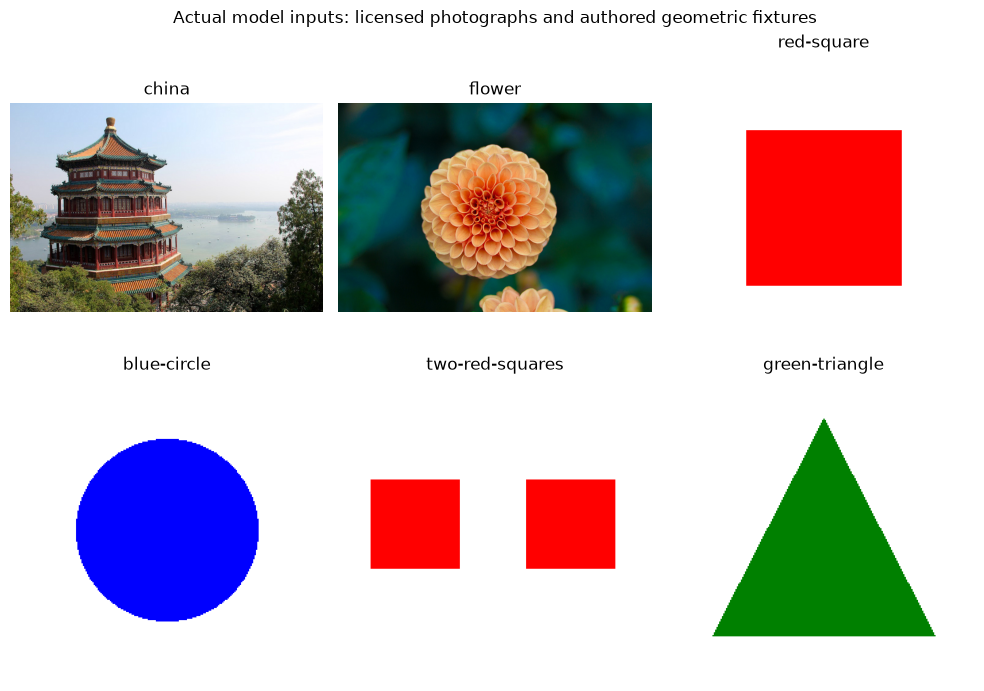

In [2]:
from uuid import uuid4
from pathlib import Path
import shutil
import sklearn
from sklearn.datasets import load_sample_image
from PIL import Image, ImageDraw
from qdrant_client import QdrantClient, models as qm
from vector_masterclass.config import qdrant_url, model_config, fingerprint
from vector_masterclass.multimodal import clip_encode
from vector_masterclass.hardware import resolve_device

ids = ["china", "flower", "red-square", "blue-circle", "two-red-squares", "green-triangle"]
images = [
    Image.fromarray(load_sample_image("china.jpg")),
    Image.fromarray(load_sample_image("flower.jpg")),
]
for kind in ids[2:]:
    canvas = Image.new("RGB", (224, 224), "white")
    draw = ImageDraw.Draw(canvas)
    if kind == "red-square":
        draw.rectangle((55, 55, 169, 169), fill="red")
    elif kind == "blue-circle":
        draw.ellipse((45, 45, 179, 179), fill="blue")
    elif kind == "two-red-squares":
        draw.rectangle((20, 75, 85, 140), fill="red")
        draw.rectangle((135, 75, 200, 140), fill="red")
    else:
        draw.polygon([(112, 30), (30, 190), (194, 190)], fill="green")
    images.append(canvas)
for id_, picture in zip(ids, images):
    picture.save(lesson.path / (id_ + ".png"))
shutil.copyfile(
    Path(sklearn.__file__).parent / "datasets/images/README.txt",
    lesson.path / "photo-attribution.txt",
)
vectors = clip_encode(images=images)
questions = [
    ("a photograph of a Chinese temple building", "china"),
    ("a photograph of a flower", "flower"),
    ("a red square on a white background", "red-square"),
    ("a blue circle on a white background", "blue-circle"),
    ("two red squares on a white background", "two-red-squares"),
    ("a green triangle on a white background", "green-triangle"),
    ("a photograph of a dog", None),
]
query_vectors = clip_encode(texts=[q for q, gold in questions])
client = QdrantClient(url=qdrant_url(), timeout=20)
name = "vmc_19c_" + uuid4().hex[:8]
client.create_collection(
    name,
    vectors_config=qm.VectorParams(size=512, distance=qm.Distance.COSINE),
    metadata={"representation": fingerprint(model_config("clip"))},
)
rows = []
try:
    client.upsert(
        name,
        points=[
            qm.PointStruct(
                id=i,
                vector=v.tolist(),
                payload={
                    "image_id": ids[i],
                    "provenance": "sklearn CC-BY-2.0 sample"
                    if i < 2
                    else "author-created geometric fixture",
                },
            )
            for i, v in enumerate(vectors)
        ],
        wait=True,
    )
    for (text, gold), query in zip(questions, query_vectors):
        hit = client.query_points(
            name,
            query=query.tolist(),
            limit=1,
            with_payload=True,
            search_params=qm.SearchParams(exact=True),
        ).points[0]
        rows.append(
            {
                "query": text,
                "expected_image": gold,
                "retrieved_image": hit.payload["image_id"],
                "cosine_score": hit.score,
                "hit_at_1": hit.payload["image_id"] == gold if gold else None,
                "unsupported_forced_return": gold is None,
            }
        )
finally:
    client.delete_collection(name)
    client.close()
results = lesson.table(pd.DataFrame(rows))
display(results)
fig, axes = plt.subplots(2, 3, figsize=(10, 7))
for ax, id_, picture in zip(axes.flat, ids, images):
    ax.imshow(picture)
    ax.set_title(id_)
    ax.axis("off")
fig.suptitle("Actual model inputs: licensed photographs and authored geometric fixtures")
fig.tight_layout()
lesson.figure(fig)
plt.show()

## Interpretation and exercise
The absent dog image still produces a nearest neighbor. Retrieval is not an existence test. Compare the red-square and two-red-squares queries for compositional confusion, even if both happen to pass this run. CLIP cosine scores are not probabilities; a softmax over a chosen label list changes with that list and is not calibrated confidence.

**Exercise:** add “a red circle” without adding such an image, then inspect the returned shape and score. Change image crop/background and compare ranking stability. Explain why layout-heavy document retrieval may need patch/token representations rather than a single global vector; lesson 23a examines that boundary.

The photographs are distributed by scikit-learn under CC BY 2.0; see `photo-attribution.txt` for original Flickr links and attribution. The upstream flower record contains inconsistent account naming, which is retained verbatim rather than silently corrected. Shapes are author-created CC0 fixtures. [CLIP model card](https://huggingface.co/openai/clip-vit-base-patch32), [original CLIP research](https://arxiv.org/abs/2103.00020). This diagnostic set does not qualify a general image-search product.

In [3]:
manifest = lesson.finish(
    {
        "real_aligned_dimensions": vectors.shape == (6, 512) and query_vectors.shape == (7, 512),
        "normalized_features": bool(np.allclose(np.linalg.norm(vectors, axis=1), 1, atol=1e-5)),
        "all_curated_queries_measured": len(results) == 7,
        "missing_image_failure_recorded": int(results.unsupported_forced_return.sum()) == 1,
        "attribution_preserved": (lesson.path / "photo-attribution.txt").exists(),
    },
    observations={
        "model": model_config("clip"),
        "device": resolve_device("clip"),
        "photo_source": "scikit-learn packaged samples; original license/attribution copied",
        "shape_source": "author-created geometric fixtures",
        "known_match_hit_rate": float(results.hit_at_1.dropna().mean()),
    },
)

{
  "artifact": "artifacts/20261031T060419Z-2fb8dd/19c",
  "checks": {
    "real_aligned_dimensions": true,
    "normalized_features": true,
    "all_curated_queries_measured": true,
    "missing_image_failure_recorded": true,
    "attribution_preserved": true,
    "process_memory_measured": true,
    "qdrant_memory_measured_when_required": true,
    "within_runtime_target": true,
    "within_conservative_memory_target": true
  }
}


## References and next steps
Consult the [Qdrant documentation](https://qdrant.tech/documentation/),
the [MiniLM model card](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2),
and [uv's Jupyter guide](https://docs.astral.sh/uv/guides/integration/jupyter/).
The exact pinned configuration is in `configs/models.json`; worked exercises are in `docs/SOLUTIONS.md`.
This notebook's measurements apply to the recorded local run, not a production deployment.